# Análisis y Testeo de Modelos de Mastitis Bovina

Este notebook documenta el análisis de los datos sintéticos (dummy data) generados basándose en las propiedades de la Finca.

## Anomalía en el Dataset: Relación Volumen de Leche vs Mastitis
> **Hallazgo Importante:** En los datos sin procesar originales, se observa que algunas vacas con mastitis tienden a tener un volumen de leche mayor. Clínicamente, la mastitis causa inflamación y daño en el tejido mamario, lo que debería reducir la producción de leche. Este patrón puede ser un artefacto del proceso de recolección de datos, un error humano en el registro, o estar condicionado por otras variables (por ejemplo, vacas de alta producción siendo más susceptibles y monitoreadas más de cerca).

Se recomienda documentar y vigilar esta variable cuando se expanda el modelo con datos en tiempo real mediante CRISP-ML(Q).


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings('ignore')

import sys
sys.path.append('../') # Para importar desde src
from src.data.dummyDataGenerator import generate_dummy_data

# Generar datos sintéticos
df = generate_dummy_data(n_samples=500, random_state=123)
df.head()

,finca,edad,raza,numero_de_partos,volumen_de_leche,etapa_de_lactancia,frecuencia_de_ordeno,estado_de_vacunacion,antecedentes_de_mastitis,humedad,temperatura,ph_leche,conductividad_leche_ms_cm,mastitis
0,Finca_1,5,Holstein,2,11.0,1,2,1,1,82.8,20.7,7.00,6.21,1
1,Finca_5,6,Holstein,4,10.9,1,2,0,1,82.9,19.6,6.80,6.18,1
2,Finca_4,8,Holstein,1,13.3,0,2,1,0,75.2,20.6,6.65,4.65,0
3,Finca_1,7,Normando,2,10.4,1,2,1,0,70.4,10.1,6.66,4.59,0
4,Finca_6,4,Holstein,5,17.0,1,2,0,0,71.7,12.3,6.65,5.17,0


### Correlación de Biomarcadores Principales
Al graficar el pH frente a la conductividad eléctrica, podemos observar claramente cómo se separan los clústeres de vacas sanas y vacas con mastitis basándonos únicamente en estos dos marcadores biológicos.

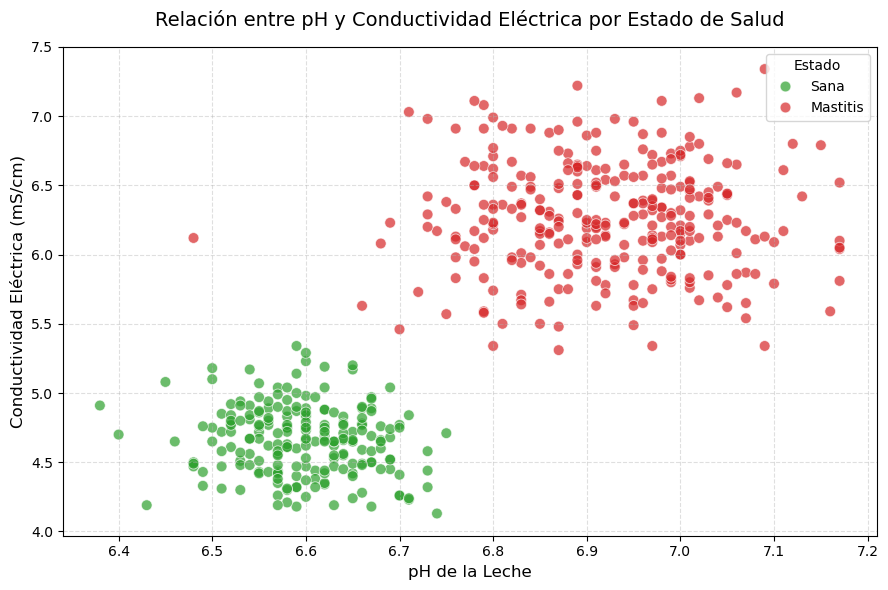

In [2]:
# Relación entre pH y Conductividad Eléctrica (Biomarcadores principales)
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, 
    x='ph_leche', 
    y='conductividad_leche_ms_cm', 
    hue='mastitis',
    palette={0: '#2ca02c', 1: '#d62728'}, # Verde para sana, Rojo para mastitis
    alpha=0.7,
    s=60
)
plt.title('Relación entre pH y Conductividad Eléctrica por Estado de Salud', fontsize=14, pad=15)
plt.xlabel('pH de la Leche', fontsize=12)
plt.ylabel('Conductividad Eléctrica (mS/cm)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.4)

# Ajustar leyenda
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles, labels=['Sana', 'Mastitis'], title='Estado', frameon=True)

plt.tight_layout()
plt.show()

## Análisis Exploratorio de Variables


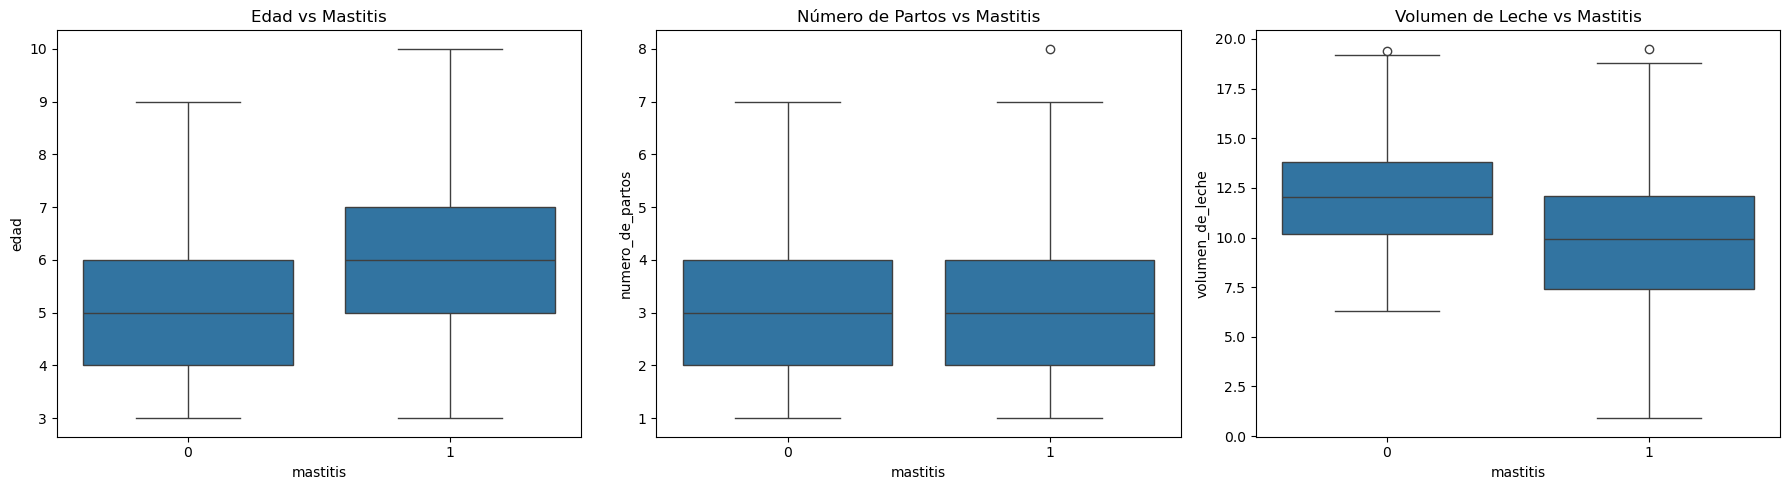

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Edad vs Mastitis
sns.boxplot(x='mastitis', y='edad', data=df, ax=axes[0])
axes[0].set_title('Edad vs Mastitis')

# Número de partos vs Mastitis
sns.boxplot(x='mastitis', y='numero_de_partos', data=df, ax=axes[1])
axes[1].set_title('Número de Partos vs Mastitis')

# Volumen vs Mastitis
sns.boxplot(x='mastitis', y='volumen_de_leche', data=df, ax=axes[2])
axes[2].set_title('Volumen de Leche vs Mastitis')

plt.tight_layout()
plt.show()

## Evaluación de Modelos (Dummy Data)


In [4]:
from pathlib import Path
from sklearn.metrics import classification_report

artifacts_dir = Path("../src/data/artifacts")
models = ["decision_tree", "random_forest", "logistic_regression"]

X_test = df.drop(columns=["finca", "mastitis"])
y_test = df["mastitis"]

for model_name in models:
    model_path = artifacts_dir / f"mastitis_{model_name}_pipeline.pkl"
    if model_path.exists():
        model = joblib.load(model_path)
        predictions = model.predict(X_test)
        print(f"--- Evaluación: {model_name.upper()} ---")
        print(classification_report(y_test, predictions, target_names=["Sana", "Mastitis"]))
    else:
        print(f"Modelo no encontrado: {model_path}")

--- Evaluación: DECISION_TREE ---
              precision    recall  f1-score   support

        Sana       0.95      0.99      0.97       208
    Mastitis       0.99      0.96      0.98       292

    accuracy                           0.97       500
   macro avg       0.97      0.98      0.97       500
weighted avg       0.97      0.97      0.97       500

--- Evaluación: RANDOM_FOREST ---
              precision    recall  f1-score   support

        Sana       0.97      1.00      0.98       208
    Mastitis       1.00      0.98      0.99       292

    accuracy                           0.99       500
   macro avg       0.98      0.99      0.99       500
weighted avg       0.99      0.99      0.99       500

--- Evaluación: LOGISTIC_REGRESSION ---
              precision    recall  f1-score   support

        Sana       1.00      1.00      1.00       208
    Mastitis       1.00      1.00      1.00       292

    accuracy                           1.00       500
   macro avg       1